In [16]:
!pip install -q split-folders gradio scikit-learn gdown

import gdown
import zipfile
import os

dosya_id = "1eroHrxH3qhcoR8ktllpdLcr5ybOVBA6K"
zip_yolu = "/content/dataset.zip"
cikartma_yolu = "/content/ham_veri"

gdown.download(id=dosya_id, output=zip_yolu, quiet=False)

with zipfile.ZipFile(zip_yolu, 'r') as zip_ref:
    zip_ref.extractall(cikartma_yolu)

kaynak_klasor = None
for root, dirs, files in os.walk(cikartma_yolu):
    hedef_alt_klasorler = [d.lower() for d in dirs]
    if 'benign' in hedef_alt_klasorler and 'malignant' in hedef_alt_klasorler:
        kaynak_klasor = root
        break

print(f"Sınıf klasörleri bulundu: {kaynak_klasor}")

Downloading...
From: https://drive.google.com/uc?id=1eroHrxH3qhcoR8ktllpdLcr5ybOVBA6K
To: /content/dataset.zip
100%|██████████| 3.22M/3.22M [00:00<00:00, 171MB/s]

Sınıf klasörleri bulundu: /content/ham_veri


In [17]:
import splitfolders

hedef_klasor = '/content/veri_seti'

splitfolders.ratio(kaynak_klasor, output=hedef_klasor, seed=42, ratio=(0.70, 0.15, 0.15))

for kume in ['train', 'val', 'test']:
    kume_yolu = os.path.join(hedef_klasor, kume)
    detay = {s: len(os.listdir(os.path.join(kume_yolu, s))) for s in os.listdir(kume_yolu)}
    print(f"{kume.upper():5s} kümesi dağılımı -> {detay}")

Copying files: 245 files [00:00, 3426.89 files/s]

TRAIN kümesi dağılımı -> {'malignant': 102, 'benign': 68}
VAL   kümesi dağılımı -> {'malignant': 22, 'benign': 14}
TEST  kümesi dağılımı -> {'malignant': 23, 'benign': 16}


In [18]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

cihaz = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan Donanım:", cihaz)

BATCH_SIZE = 32
LEARNING_RATE = 1e-4
EPOCHS = 15
INPUT_SIZE = 224

# Ön İşleme
veri_donusumleri = {
    'train': transforms.Compose([
        transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

goruntu_kumeleri = {x: datasets.ImageFolder(os.path.join(hedef_klasor, x), veri_donusumleri[x])
                    for x in ['train', 'val', 'test']}

yukleyiciler = {x: DataLoader(goruntu_kumeleri[x], batch_size=BATCH_SIZE, shuffle=(x=='train'), num_workers=2)
                for x in ['train', 'val', 'test']}

sinif_isimleri = goruntu_kumeleri['train'].classes
sinif_sayisi = len(sinif_isimleri)
print(f"Sınıflar ({sinif_sayisi} adet):", sinif_isimleri)

# ResNet-50
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, sinif_sayisi)
model = model.to(cihaz)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)

# Eğitim Döngüsü
egitim_gecmisi = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
baslangic = time.time()
en_iyi_agirliklar = copy.deepcopy(model.state_dict())
en_iyi_val_acc = 0.0

for epoch in range(EPOCHS):
    print(f"Epoch {epoch+1}/{EPOCHS}")
    for asama in ['train', 'val']:
        model.train() if asama == 'train' else model.eval()
        toplam_kayip = 0.0
        dogru = 0

        for girdiler, etiketler in yukleyiciler[asama]:
            girdiler, etiketler = girdiler.to(cihaz), etiketler.to(cihaz)
            optimizer.zero_grad()

            with torch.set_grad_enabled(asama == 'train'):
                ciktilar = model(girdiler)
                _, tahminler = torch.max(ciktilar, 1)
                kayip = criterion(ciktilar, etiketler)

                if asama == 'train':
                    kayip.backward()
                    optimizer.step()

            toplam_kayip += kayip.item() * girdiler.size(0)
            dogru += torch.sum(tahminler == etiketler.data)

        epoch_kayip = toplam_kayip / len(goruntu_kumeleri[asama])
        epoch_acc = (dogru.double() / len(goruntu_kumeleri[asama])).item()
        egitim_gecmisi[f'{asama}_loss'].append(epoch_kayip)
        egitim_gecmisi[f'{asama}_acc'].append(epoch_acc)

        print(f"  {asama.upper():5s} -> Loss: {epoch_kayip:.4f} | Accuracy: {epoch_acc:.4f}")

        if asama == 'val' and epoch_acc > en_iyi_val_acc:
            en_iyi_val_acc = epoch_acc
            en_iyi_agirliklar = copy.deepcopy(model.state_dict())

egitim_suresi = time.time() - baslangic
print(f"\nEğitim Tamamlandı! Toplam Süre: {egitim_suresi // 60:.0f} dk {egitim_suresi % 60:.1f} sn")
print(f"En İyi Doğrulama (Validation) Accuracy: {en_iyi_val_acc:.4f}")

model.load_state_dict(en_iyi_agirliklar)
torch.save(model.state_dict(), '/content/ultrason_resnet50_best.pth')

Kullanılan Donanım: cuda
Sınıflar (2 adet): ['benign', 'malignant']
Epoch 1/15
  TRAIN -> Loss: 0.6551 | Accuracy: 0.6941
  VAL   -> Loss: 0.6869 | Accuracy: 0.6111
Epoch 2/15
  TRAIN -> Loss: 0.5234 | Accuracy: 0.8118
  VAL   -> Loss: 0.6555 | Accuracy: 0.6111
Epoch 3/15
  TRAIN -> Loss: 0.3987 | Accuracy: 0.9000
  VAL   -> Loss: 0.5599 | Accuracy: 0.6944
Epoch 4/15
  TRAIN -> Loss: 0.3069 | Accuracy: 0.9000
  VAL   -> Loss: 0.4625 | Accuracy: 0.7222
Epoch 5/15
  TRAIN -> Loss: 0.2462 | Accuracy: 0.9176
  VAL   -> Loss: 0.3856 | Accuracy: 0.8889
Epoch 6/15
  TRAIN -> Loss: 0.2264 | Accuracy: 0.9000
  VAL   -> Loss: 0.3270 | Accuracy: 0.9722
Epoch 7/15
  TRAIN -> Loss: 0.1689 | Accuracy: 0.9353
  VAL   -> Loss: 0.2725 | Accuracy: 0.9722
Epoch 8/15
  TRAIN -> Loss: 0.1470 | Accuracy: 0.9529
  VAL   -> Loss: 0.2167 | Accuracy: 0.9444
Epoch 9/15
  TRAIN -> Loss: 0.1151 | Accuracy: 0.9647
  VAL   -> Loss: 0.1728 | Accuracy: 0.9444
Epoch 10/15
  TRAIN -> Loss: 0.0748 | Accuracy: 0.9882
  VA

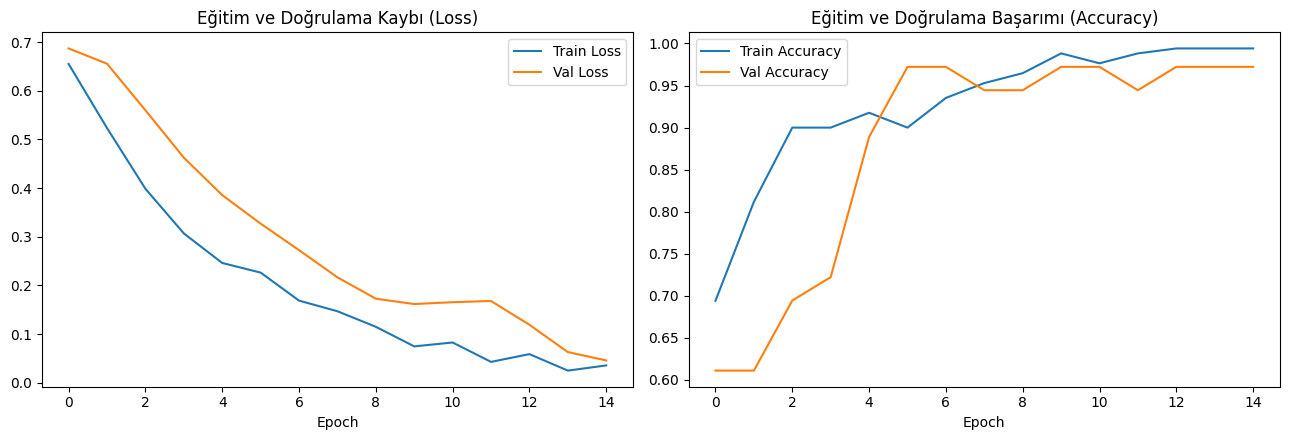


================ TEST METRİKLERİ ================
Accuracy  : 0.8718 (%87.18)
Precision : 0.8708
Recall    : 0.8628
F1-Score  : 0.8662
Tahmin Süresi (Inference Time): 13.26 ms / görüntü

Detaylı Rapor:
               precision    recall  f1-score   support

      benign       0.87      0.81      0.84        16
   malignant       0.88      0.91      0.89        23

    accuracy                           0.87        39
   macro avg       0.87      0.86      0.87        39
weighted avg       0.87      0.87      0.87        39



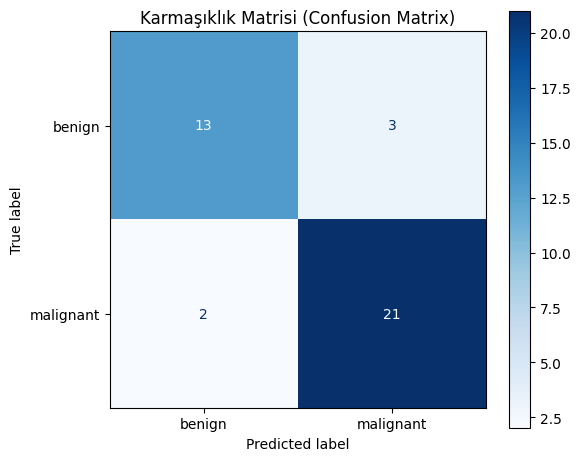

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, classification_report

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(egitim_gecmisi['train_loss'], label='Train Loss')
ax1.plot(egitim_gecmisi['val_loss'], label='Val Loss')
ax1.set_title('Eğitim ve Doğrulama Kaybı (Loss)')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(egitim_gecmisi['train_acc'], label='Train Accuracy')
ax2.plot(egitim_gecmisi['val_acc'], label='Val Accuracy')
ax2.set_title('Eğitim ve Doğrulama Başarımı (Accuracy)')
ax2.set_xlabel('Epoch')
ax2.legend()
plt.tight_layout()
plt.savefig('egitim_grafikleri.png', dpi=300)
plt.show()

model.eval()
tum_tahminler, tum_etiketler = [], []

tahmin_baslangic = time.time()
with torch.no_grad():
    for girdiler, etiketler in yukleyiciler['test']:
        girdiler = girdiler.to(cihaz)
        ciktilar = model(girdiler)
        _, tahminler = torch.max(ciktilar, 1)
        tum_tahminler.extend(tahminler.cpu().numpy())
        tum_etiketler.extend(etiketler.numpy())

toplam_tahmin_suresi = time.time() - tahmin_baslangic
inference_ms = (toplam_tahmin_suresi / len(goruntu_kumeleri['test'])) * 1000

acc = accuracy_score(tum_etiketler, tum_tahminler)
precision, recall, f1, _ = precision_recall_fscore_support(tum_etiketler, tum_tahminler, average='macro')

print("\n================ TEST METRİKLERİ ================")
print(f"Accuracy  : {acc:.4f} (%{acc*100:.2f})")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"Tahmin Süresi (Inference Time): {inference_ms:.2f} ms / görüntü")
print("======================================================================\n")
print("Detaylı Rapor:\n", classification_report(tum_etiketler, tum_tahminler, target_names=sinif_isimleri))


cm = confusion_matrix(tum_etiketler, tum_tahminler)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sinif_isimleri).plot(cmap='Blues', ax=ax)
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

5 görüntüyü bilgisayardan seçip yükleyiniz:


Saving 3_malignant.bmp to 3_malignant (4).bmp
Saving 4_malignant.bmp to 4_malignant (4).bmp
Saving 1_benign.bmp to 1_benign (4).bmp
Saving 5_malignant.bmp to 5_malignant (4).bmp
Saving 2_benign.bmp to 2_benign (4).bmp

================ GÖRÜNTÜ KARŞILAŞTIRMA TABLOSU ================
Dosya Adı                 | Gerçek Sınıf | Model Tahmini | Güven    | Sonuç
---------------------------------------------------------------------------
3_malignant (4).bmp       | malignant    | malignant     | % 72.3  | DOĞRU
4_malignant (4).bmp       | malignant    | malignant     | % 81.7  | DOĞRU
1_benign (4).bmp          | benign       | benign        | % 70.9  | DOĞRU
5_malignant (4).bmp       | malignant    | malignant     | % 56.3  | DOĞRU
2_benign (4).bmp          | benign       | benign        | % 52.3  | DOĞRU


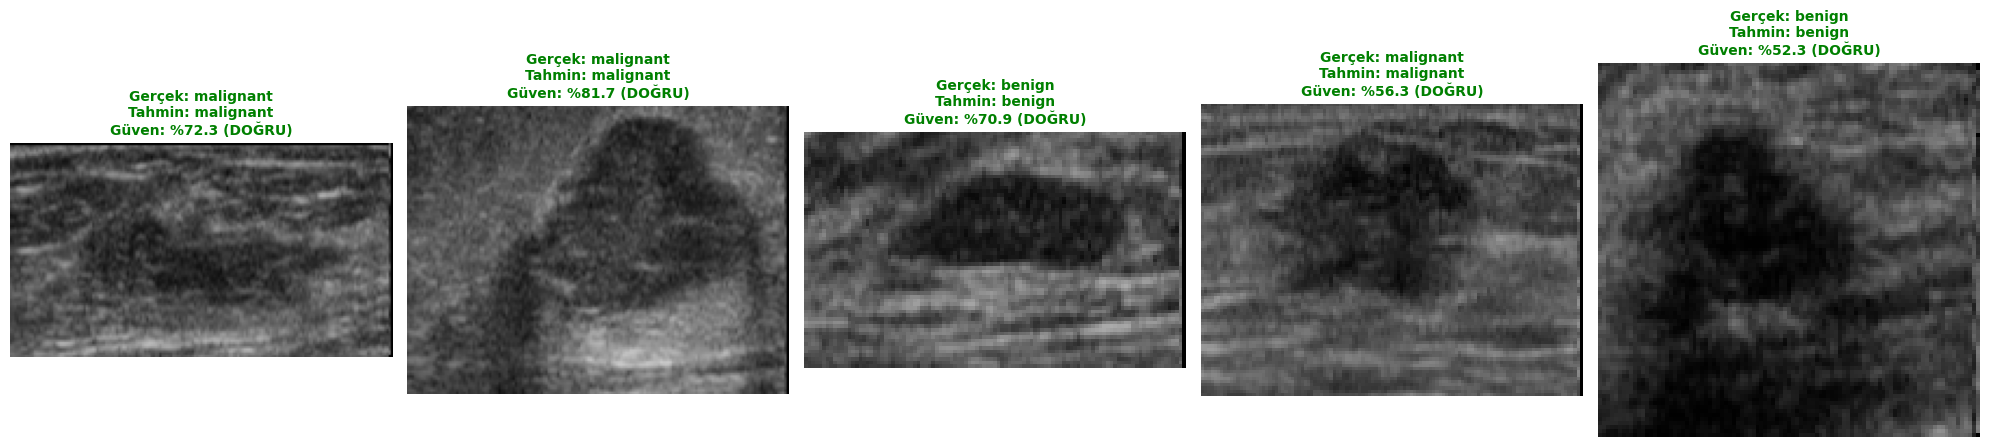


Görsel kaydedildi


In [20]:
from google.colab import files
from PIL import Image
import torch.nn.functional as F

print("5 görüntüyü bilgisayardan seçip yükleyiniz:")
yuklenen_dosyalar = files.upload()

adet = len(yuklenen_dosyalar)
fig, axes = plt.subplots(1, adet, figsize=(4 * adet, 5))
if adet == 1:
    axes = [axes]

print("\n================ GÖRÜNTÜ KARŞILAŞTIRMA TABLOSU ================")
print(f"{'Dosya Adı':<25} | {'Gerçek Sınıf':<12} | {'Model Tahmini':<13} | {'Güven':<8} | {'Sonuç'}")
print("-" * 75)

for idx, dosya_adi in enumerate(yuklenen_dosyalar.keys()):
    img = Image.open(dosya_adi).convert('RGB')
    input_tensor = veri_donusumleri['test'](img).unsqueeze(0).to(cihaz)

    model.eval()
    with torch.no_grad():
        cikti = model(input_tensor)
        olasiliklar = F.softmax(cikti, dim=1)[0]
        guven, tahmin_idx = torch.max(olasiliklar, 0)

    tahmin_sinif = sinif_isimleri[tahmin_idx.item()]

    dosya_kucuk = dosya_adi.lower()
    if 'malignant' in dosya_kucuk:
        gercek_sinif = 'malignant'
    elif 'benign' in dosya_kucuk:
        gercek_sinif = 'benign'
    else:
        print("gercek sinif bulunamadi!");

    dogru_mu = (tahmin_sinif.lower() == gercek_sinif.lower())
    durum_metni = "DOĞRU" if dogru_mu else "YANLIŞ"
    baslik_rengi = "green" if dogru_mu else "red"

    print(f"{dosya_adi[:25]:<25} | {gercek_sinif:<12} | {tahmin_sinif:<13} | %{guven.item()*100:5.1f}  | {durum_metni}")

    axes[idx].imshow(img)
    axes[idx].axis('off')
    axes[idx].set_title(
        f"Gerçek: {gercek_sinif}\nTahmin: {tahmin_sinif}\nGüven: %{guven.item()*100:.1f} ({durum_metni})",
        fontsize=10, color=baslik_rengi, fontweight='bold'
    )

plt.tight_layout()
plt.savefig("bes_goruntu_test_sonucu.png", dpi=300)
plt.show()
print("\nGörsel kaydedildi");

In [21]:
import gradio as gr

def ultrason_siniflandir(image):
    if image is None:
        return None
    img = Image.fromarray(image).convert('RGB')
    input_tensor = veri_donusumleri['test'](img).unsqueeze(0).to(cihaz)

    model.eval()
    with torch.no_grad():
        cikti = model(input_tensor)
        olasiliklar = F.softmax(cikti, dim=1)[0]

    return {sinif_isimleri[i]: float(olasiliklar[i]) for i in range(sinif_sayisi)}

uygulama = gr.Interface(
    fn=ultrason_siniflandir,
    inputs=gr.Image(label="Ultrason Görüntüsü Yükleyin (.bmp, .jpg, .png)"),
    outputs=gr.Label(num_top_classes=2, label="Sınıflandırma"),
    title="Ultrason Tümör Sınıflandırması",
    description="Yüklenen ultrason görüntüsünün Benign (iyi huylu) veya Malignant (kötü huylu) olma olasılığını analiz eden model"
)

uygulama.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7b82d427b325b39887.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
